# Wavelet-Based Multiscale Analysis of ECG and PPG Signals

**Objective:**  
To investigate the multiscale structure of physiological signals using
Discrete Wavelet Transform (DWT), Continuous Wavelet Transform (CWT),
and wavelet-based denoising, with emphasis on information preservation
and scale-dependent signal quality.

Records containing both ECG and PPG were searched from the downloaded
MIMIC-IV waveform data.

Candidate segments were screened based on:
- Suitable duration
- Non-flat signal variation
- Visual signal quality

After screening, record **81739927_0012** was selected.

- Record: 81739927_0012
- ECG: Lead II
- PPG: Pleth
- Sampling frequency: 62.4725 Hz
- Time window: 10–18 seconds
- Samples: 500

In [2]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

record_path = r"E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0012"

fs = 62.4725
start_sec = 10
end_sec = 18

start_sample = int(start_sec * fs)
end_sample = int(end_sec * fs)

record = wfdb.rdrecord(
    record_path,
    sampfrom=start_sample,
    sampto=end_sample
)

ecg = record.p_signal[:, record.sig_name.index("II")]
ppg = record.p_signal[:, record.sig_name.index("Pleth")]

time = np.arange(len(ecg)) / fs

print("ECG samples:", len(ecg))
print("PPG samples:", len(ppg))
print("Sampling frequency:", fs)

ECG samples: 500
PPG samples: 500
Sampling frequency: 62.4725


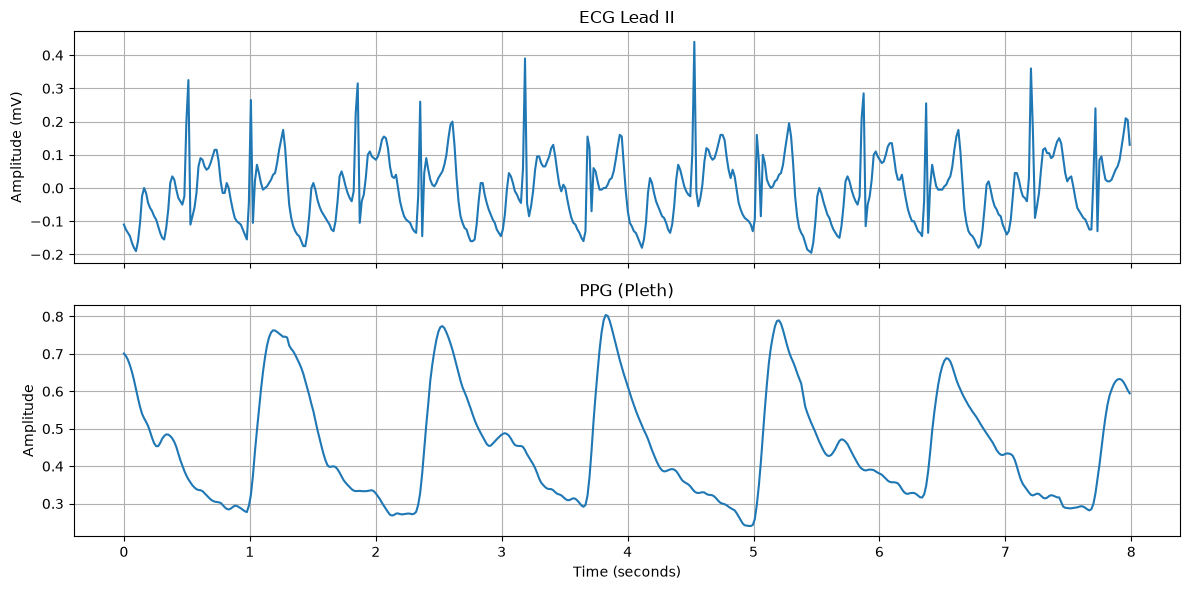

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(time, ecg)
axes[0].set_title("ECG Lead II")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(True)

axes[1].plot(time, ppg)
axes[1].set_title("PPG (Pleth)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Observation

The selected ECG and PPG segments show clear temporal variation and
repeated physiological patterns. The ECG contains distinct sharp
cardiac peaks, while the PPG shows a clear periodic pulse waveform.
Therefore, this segment is suitable for further multiscale wavelet
analysis.

## 4. Discrete Wavelet Transform (DWT)

DWT decomposes the signal into two components at each level:

- **Approximation (cA):** low-frequency / slower signal variations
- **Detail (cD):** high-frequency / faster signal variations

The decomposition allows the signal to be studied at different scales.

In [4]:
import pywt

# Haar wavelet
cA1, cD1 = pywt.dwt(ecg, "haar")

print("Original samples:", len(ecg))
print("Approximation coefficients (cA1):", len(cA1))
print("Detail coefficients (cD1):", len(cD1))


Original samples: 500
Approximation coefficients (cA1): 250
Detail coefficients (cD1): 250


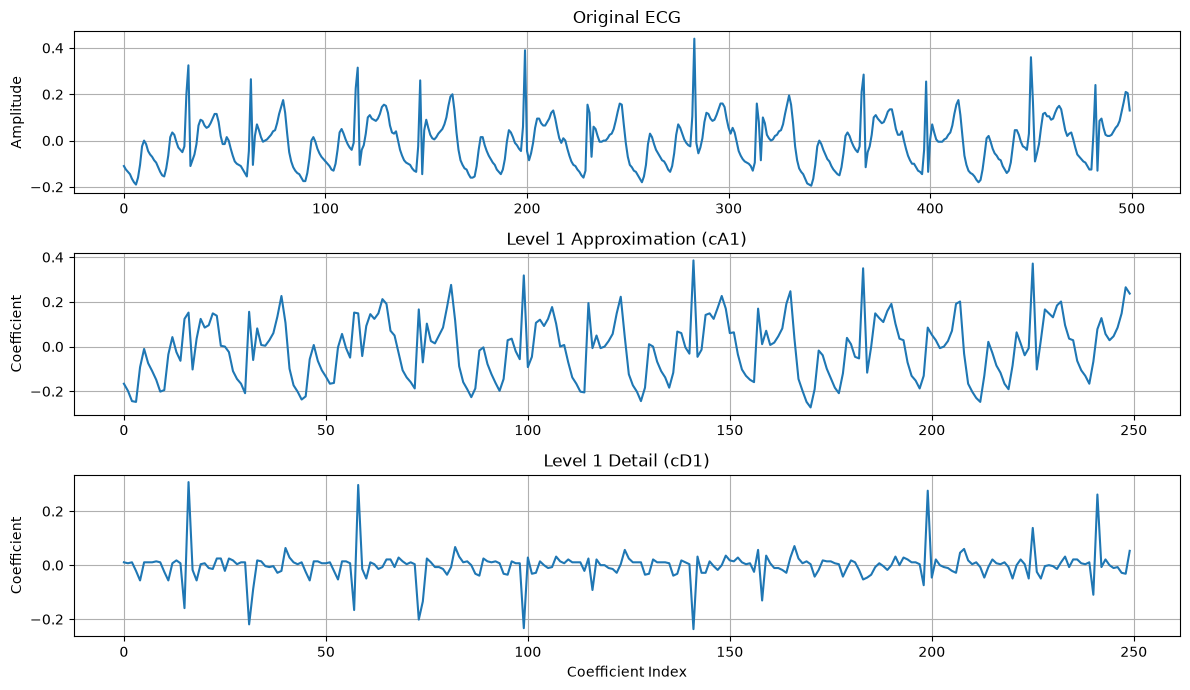

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))

axes[0].plot(ecg)
axes[0].set_title("Original ECG")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(cA1)
axes[1].set_title("Level 1 Approximation (cA1)")
axes[1].set_ylabel("Coefficient")
axes[1].grid(True)

axes[2].plot(cD1)
axes[2].set_title("Level 1 Detail (cD1)")
axes[2].set_xlabel("Coefficient Index")
axes[2].set_ylabel("Coefficient")
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [6]:
cA2, cD2 = pywt.dwt(cA1, "haar")

print("Level 1 approximation:", len(cA1))
print("Level 2 approximation:", len(cA2))
print("Level 2 detail:", len(cD2))


Level 1 approximation: 250
Level 2 approximation: 125
Level 2 detail: 125


### Observation

The Level-2 decomposition further separates the Level-1 approximation
into a coarser approximation (cA2) and detail coefficients (cD2).
Thus, different decomposition levels represent the ECG at different
scales.

In [7]:
cA3, cD3 = pywt.dwt(cA2, "haar")

print("cA1:", len(cA1))
print("cD1:", len(cD1))
print("cA2:", len(cA2))
print("cD2:", len(cD2))
print("cA3:", len(cA3))
print("cD3:", len(cD3))


cA1: 250
cD1: 250
cA2: 125
cD2: 125
cA3: 63
cD3: 63


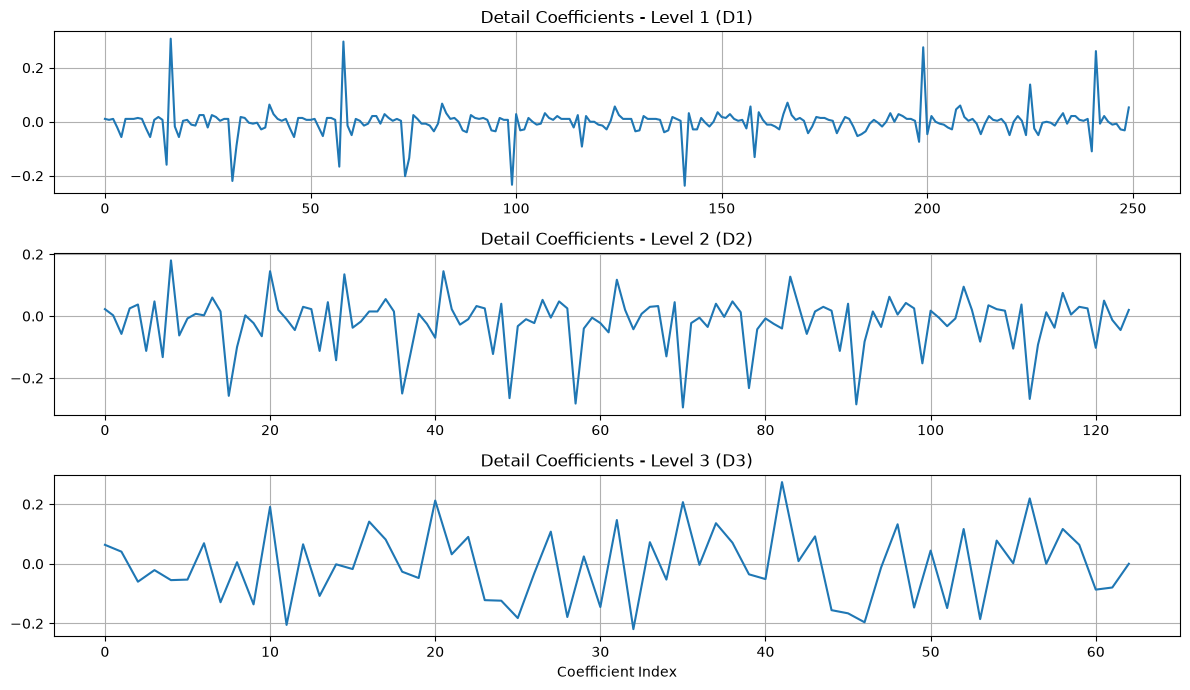

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))

axes[0].plot(cD1)
axes[0].set_title("Detail Coefficients - Level 1 (D1)")
axes[0].grid(True)

axes[1].plot(cD2)
axes[1].set_title("Detail Coefficients - Level 2 (D2)")
axes[1].grid(True)

axes[2].plot(cD3)
axes[2].set_title("Detail Coefficients - Level 3 (D3)")
axes[2].set_xlabel("Coefficient Index")
axes[2].grid(True)

plt.tight_layout()
plt.show()


### Observation

The detail coefficients become progressively coarser from D1 to D3,
while the number of coefficients decreases at each level. This
demonstrates the multiscale representation of the ECG signal.


In [9]:
energy_D1 = np.sum(cD1 ** 2)
energy_D2 = np.sum(cD2 ** 2)
energy_D3 = np.sum(cD3 ** 2)
energy_A3 = np.sum(cA3 ** 2)

energies = {
    "D1": energy_D1,
    "D2": energy_D2,
    "D3": energy_D3,
    "A3": energy_A3
}

for name, value in energies.items():
    print(f"{name}: {value:.4f}")

D1: 0.7983
D2: 1.0093
D3: 0.8822
A3: 2.8584


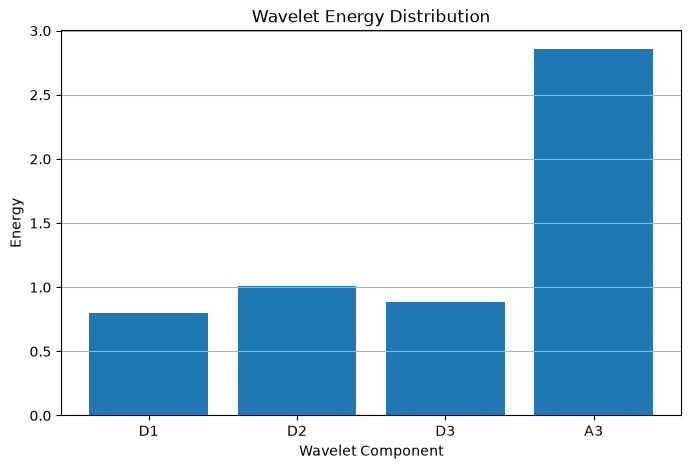

In [10]:
labels = ["D1", "D2", "D3", "A3"]
values = [energy_D1, energy_D2, energy_D3, energy_A3]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)

plt.title("Wavelet Energy Distribution")
plt.xlabel("Wavelet Component")
plt.ylabel("Energy")
plt.grid(axis="y")

plt.show()

In [11]:
total_energy = sum(energies.values())

relative_energy = {
    name: (value / total_energy) * 100
    for name, value in energies.items()
}

for name, value in relative_energy.items():
    print(f"{name}: {value:.2f}%")

D1: 14.39%
D2: 18.19%
D3: 15.90%
A3: 51.52%


In [12]:
def wavelet_entropy(coefficients):
    energy = coefficients ** 2
    probability = energy / np.sum(energy)
    
    probability = probability[probability > 0]
    
    return -np.sum(probability * np.log2(probability))


entropy_D1 = wavelet_entropy(cD1)
entropy_D2 = wavelet_entropy(cD2)
entropy_D3 = wavelet_entropy(cD3)
entropy_A3 = wavelet_entropy(cA3)

entropies = {
    "D1": entropy_D1,
    "D2": entropy_D2,
    "D3": entropy_D3,
    "A3": entropy_A3
}

for name, value in entropies.items():
    print(f"{name}: {value:.4f}")

D1: 4.8290
D2: 5.0598
D3: 5.1082
A3: 5.2684


### Observation

Wavelet entropy varies across the decomposition components, indicating
that the coefficient energy is distributed differently at different
scales. The highest entropy is observed in A3, while D1 has the lowest
entropy among the analyzed components.

In [13]:
wavelets = {
    "Haar": "haar",
    "Daubechies": "db4",
    "Symlet": "sym4",
    "Coiflet": "coif1"
}

wavelet_results = {}

for name, wavelet in wavelets.items():
    cA, cD = pywt.dwt(ecg, wavelet)
    wavelet_results[name] = (cA, cD)
    print(f"{name}: cA = {len(cA)}, cD = {len(cD)}")

Haar: cA = 250, cD = 250
Daubechies: cA = 253, cD = 253
Symlet: cA = 253, cD = 253
Coiflet: cA = 252, cD = 252


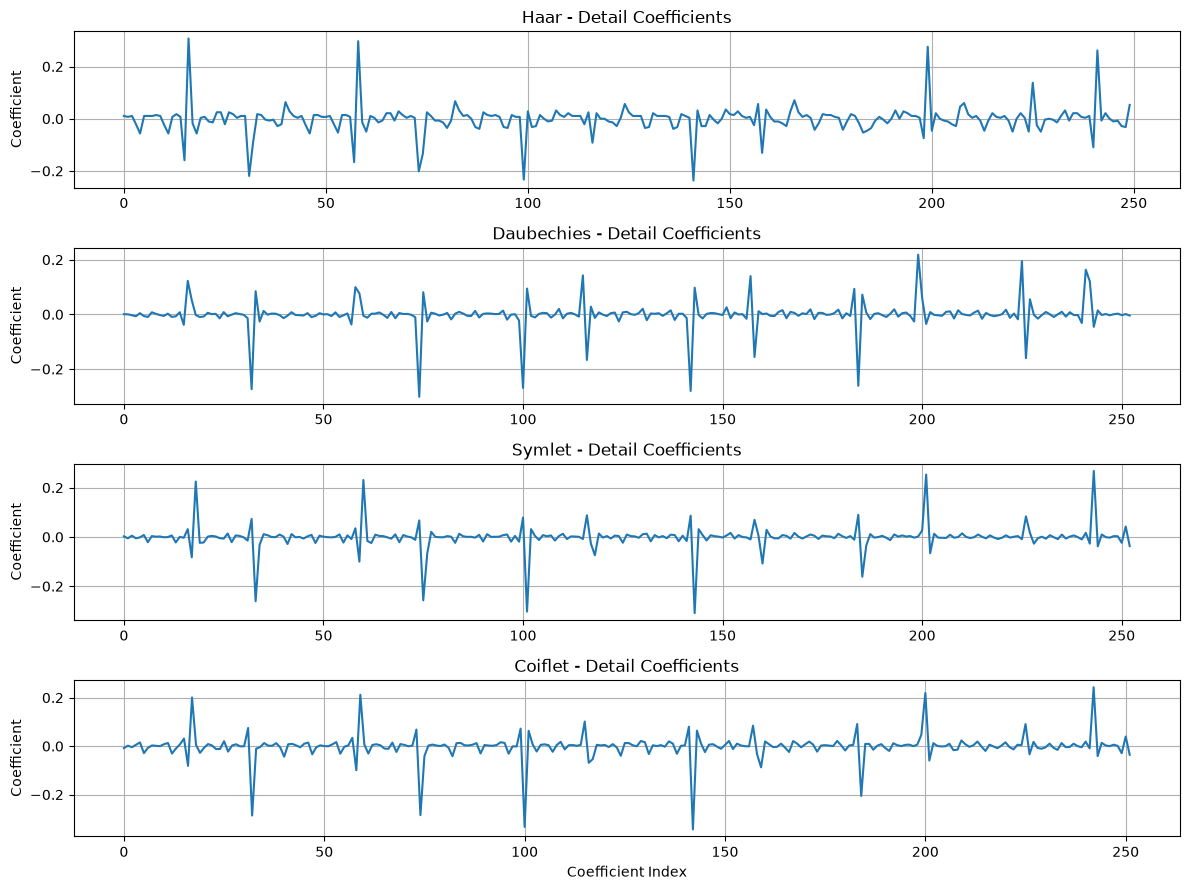

In [14]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9))

for ax, (name, (cA, cD)) in zip(axes, wavelet_results.items()):
    ax.plot(cD)
    ax.set_title(f"{name} - Detail Coefficients")
    ax.set_ylabel("Coefficient")
    ax.grid(True)

axes[-1].set_xlabel("Coefficient Index")

plt.tight_layout()
plt.show()

### Observation

Different wavelet families produce different detail-coefficient
representations of the same ECG signal. The major signal variations
are visible across all four wavelets, but their coefficient patterns
and amplitudes differ.

In [15]:
wavelet_energy = {}

for name, (cA, cD) in wavelet_results.items():
    wavelet_energy[name] = np.sum(cD ** 2)

for name, energy in wavelet_energy.items():
    print(f"{name}: {energy:.4f}")

Haar: 0.7983
Daubechies: 0.7424
Symlet: 0.7146
Coiflet: 0.7755


### Observation

The choice of wavelet affects the distribution of ECG information in
the detail coefficients. For the selected segment, the detail energy
varies across the four wavelet families. Therefore, wavelet selection
can influence the representation of ECG features at different scales.

In [16]:
reconstructed = {}

for name, (cA, cD) in wavelet_results.items():
    reconstructed[name] = pywt.idwt(cA, cD, wavelets[name])
    print(name, ":", len(reconstructed[name]))

Haar : 500
Daubechies : 500
Symlet : 500
Coiflet : 500


In [17]:
for name, rec in reconstructed.items():
    rmse = np.sqrt(np.mean((ecg - rec) ** 2))
    correlation = np.corrcoef(ecg, rec)[0, 1]

    print(f"{name}:")
    print(f"  RMSE = {rmse:.8f}")
    print(f"  Correlation = {correlation:.6f}")

Haar:
  RMSE = 0.00000000
  Correlation = 1.000000
Daubechies:
  RMSE = 0.00000000
  Correlation = 1.000000
Symlet:
  RMSE = 0.00000000
  Correlation = 1.000000
Coiflet:
  RMSE = 0.00000000
  Correlation = 1.000000


### Observation

The original ECG was successfully reconstructed using all four wavelet
families. The reconstructed signals showed negligible reconstruction
error (RMSE ≈ 0) and correlation ≈ 1 with the original ECG.

This indicates that the DWT coefficients preserve the signal information
when they are fully retained.

In [18]:
threshold = 0.1

print("Threshold:", threshold)

Threshold: 0.1


In [19]:
# 3-level Haar decomposition
coeffs = pywt.wavedec(ecg, "haar", level=3)

# coeffs = [cA3, cD3, cD2, cD1]

# Hard threshold only the detail coefficients
coeffs_hard = [coeffs[0]]

for detail in coeffs[1:]:
    coeffs_hard.append(
        pywt.threshold(detail, threshold, mode="hard")
    )

# Reconstruct
ecg_hard = pywt.waverec(coeffs_hard, "haar")

print("Original length:", len(ecg))
print("Denoised length:", len(ecg_hard))

Original length: 500
Denoised length: 500


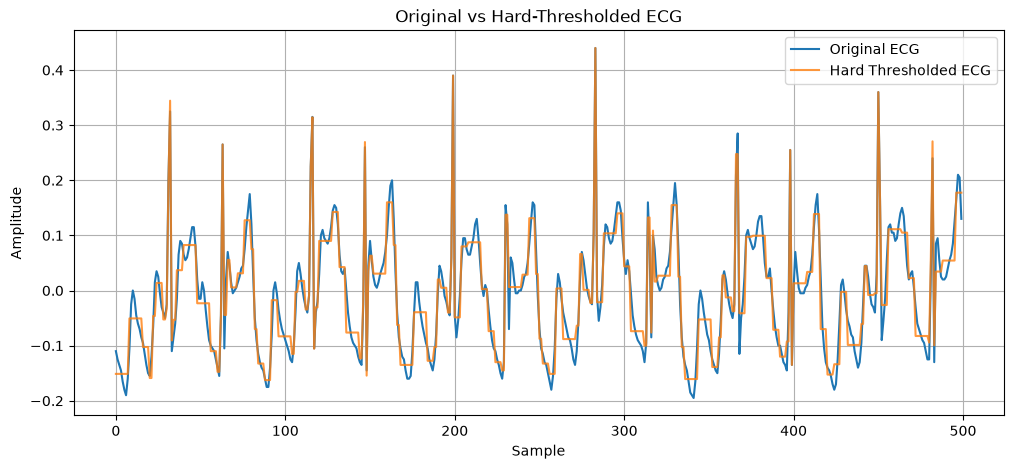

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_hard, label="Hard Thresholded ECG", alpha=0.8)

plt.title("Original vs Hard-Thresholded ECG")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

### Observation

Hard thresholding removes smaller wavelet coefficients while retaining
larger coefficients. The reconstructed ECG remains similar to the
original signal, while some smaller variations are reduced.

In [21]:
coeffs_soft = [coeffs[0]]

for detail in coeffs[1:]:
    coeffs_soft.append(
        pywt.threshold(detail, threshold, mode="soft")
    )

ecg_soft = pywt.waverec(coeffs_soft, "haar")

print("Original length:", len(ecg))
print("Soft-denoised length:", len(ecg_soft))

Original length: 500
Soft-denoised length: 500


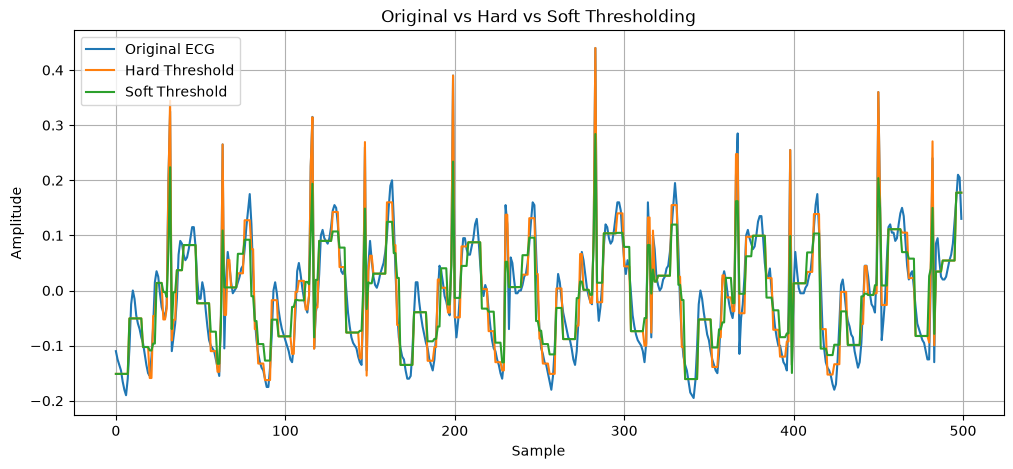

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_hard, label="Hard Threshold")
plt.plot(ecg_soft, label="Soft Threshold")

plt.title("Original vs Hard vs Soft Thresholding")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
for name, signal in {
    "Hard Threshold": ecg_hard,
    "Soft Threshold": ecg_soft
}.items():

    rmse = np.sqrt(np.mean((ecg - signal) ** 2))
    mae = np.mean(np.abs(ecg - signal))
    correlation = np.corrcoef(ecg, signal)[0, 1]

    print(name)
    print(f"RMSE        : {rmse:.6f}")
    print(f"MAE         : {mae:.6f}")
    print(f"Correlation : {correlation:.6f}")
    print()

Hard Threshold
RMSE        : 0.027776
MAE         : 0.021805
Correlation : 0.963670

Soft Threshold
RMSE        : 0.046168
MAE         : 0.036208
Correlation : 0.903918



### Quantitative Comparison

For the selected ECG segment, hard thresholding produced lower RMSE and
MAE and higher correlation than soft thresholding at a threshold of 0.1.

This indicates that, for this particular threshold and signal segment,
hard thresholding introduced less change to the original ECG waveform.

In [24]:
# Use finest detail coefficients to estimate noise
sigma = np.median(np.abs(coeffs[-1])) / 0.6745

# Universal threshold
universal_threshold = sigma * np.sqrt(2 * np.log(len(ecg)))

print("Estimated noise level (sigma):", sigma)
print("Universal threshold:", universal_threshold)

Estimated noise level (sigma): 0.020966843029994006
Universal threshold: 0.07391880120142134


In [25]:
coeffs_universal = [coeffs[0]]

for detail in coeffs[1:]:
    coeffs_universal.append(
        pywt.threshold(
            detail,
            universal_threshold,
            mode="hard"
        )
    )

ecg_universal = pywt.waverec(
    coeffs_universal,
    "haar"
)

print("Length:", len(ecg_universal))

Length: 500


In [26]:
rmse_universal = np.sqrt(np.mean((ecg - ecg_universal) ** 2))
mae_universal = np.mean(np.abs(ecg - ecg_universal))
corr_universal = np.corrcoef(ecg, ecg_universal)[0, 1]

print("Universal Threshold:")
print(f"RMSE        : {rmse_universal:.6f}")
print(f"MAE         : {mae_universal:.6f}")
print(f"Correlation : {corr_universal:.6f}")

Universal Threshold:
RMSE        : 0.023836
MAE         : 0.018818
Correlation : 0.973376


In [30]:
# Estimate noise from finest detail coefficients
sigma = np.median(np.abs(coeffs[-1])) / 0.6745
noise_var = sigma ** 2

bayes_thresholds = []

for detail in coeffs[1:]:
    signal_var = max(np.var(detail) - noise_var, 0)

    if signal_var == 0:
        threshold_bayes = np.max(np.abs(detail))
    else:
        threshold_bayes = noise_var / np.sqrt(signal_var)

    bayes_thresholds.append(threshold_bayes)

print("Noise sigma:", sigma)
print("BayesShrink thresholds:")

for i, value in enumerate(bayes_thresholds, start=1):
    print(f"D{i}: {value:.6f}")

Noise sigma: 0.020966843029994006
BayesShrink thresholds:
D1: 0.003777
D2: 0.005159
D3: 0.008380


In [31]:
coeffs_bayes = [coeffs[0]]

for detail, thr in zip(coeffs[1:], bayes_thresholds):
    coeffs_bayes.append(
        pywt.threshold(detail, thr, mode="soft")
    )

ecg_bayes = pywt.waverec(coeffs_bayes, "haar")

print("Original length:", len(ecg))
print("BayesShrink length:", len(ecg_bayes))

Original length: 500
BayesShrink length: 500


In [32]:
rmse_bayes = np.sqrt(np.mean((ecg - ecg_bayes) ** 2))
mae_bayes = np.mean(np.abs(ecg - ecg_bayes))

nrmse_bayes = rmse_bayes / (np.max(ecg) - np.min(ecg))

prd_bayes = (
    np.sqrt(np.sum((ecg - ecg_bayes) ** 2) / np.sum(ecg ** 2))
    * 100
)

corr_bayes = np.corrcoef(ecg, ecg_bayes)[0, 1]

print("BayesShrink:")
print(f"RMSE        : {rmse_bayes:.6f}")
print(f"MAE         : {mae_bayes:.6f}")
print(f"NRMSE       : {nrmse_bayes:.6f}")
print(f"PRD         : {prd_bayes:.4f}%")
print(f"Correlation : {corr_bayes:.6f}")

BayesShrink:
RMSE        : 0.006150
MAE         : 0.005439
NRMSE       : 0.009684
PRD         : 5.9053%
Correlation : 0.998444


### Threshold-Selection Comparison

Three threshold-selection approaches were evaluated: a fixed threshold,
Universal Threshold, and BayesShrink.

For the selected ECG segment, BayesShrink produced the lowest RMSE, MAE,
NRMSE and PRD, along with the highest correlation with the original
signal. Therefore, it provided the best signal preservation among the
tested approaches for this segment.

In [33]:
# CWT of ECG using Morlet wavelet
# Frequency range for final CWT analysis
freq_min = 1
freq_max = 30

# Morlet scales
scales_morl = np.arange(1, 64)
freq_morl = pywt.scale2frequency("morl", scales_morl) * fs

# Mexican Hat scales
scales_mexh = np.arange(1, 64)
freq_mexh = pywt.scale2frequency("mexh", scales_mexh) * fs

print("Morlet frequency range:",
      freq_morl.min(), "to", freq_morl.max(), "Hz")

print("Mexican Hat frequency range:",
      freq_mexh.min(), "to", freq_mexh.max(), "Hz")

Morlet frequency range: 0.8056969246031745 to 50.758906249999995 Hz
Mexican Hat frequency range: 0.247906746031746 to 15.618125 Hz


In [35]:
# Common frequency range for fair CWT comparison

target_freqs = np.geomspace(1, 30, 64)

# Convert frequencies to scales for each wavelet
scales_morl = pywt.frequency2scale("morl", target_freqs / fs)
scales_mexh = pywt.frequency2scale("mexh", target_freqs / fs)

# CWT
cwt_morl, freq_morl = pywt.cwt(
    ecg, scales_morl, "morl", sampling_period=1/fs
)

cwt_mexh, freq_mexh = pywt.cwt(
    ecg, scales_mexh, "mexh", sampling_period=1/fs
)

print("Morlet:", freq_morl.min(), "to", freq_morl.max(), "Hz")
print("Mexican Hat:", freq_mexh.min(), "to", freq_mexh.max(), "Hz")

Morlet: 1.0 to 30.0 Hz
Mexican Hat: 1.0 to 30.0 Hz


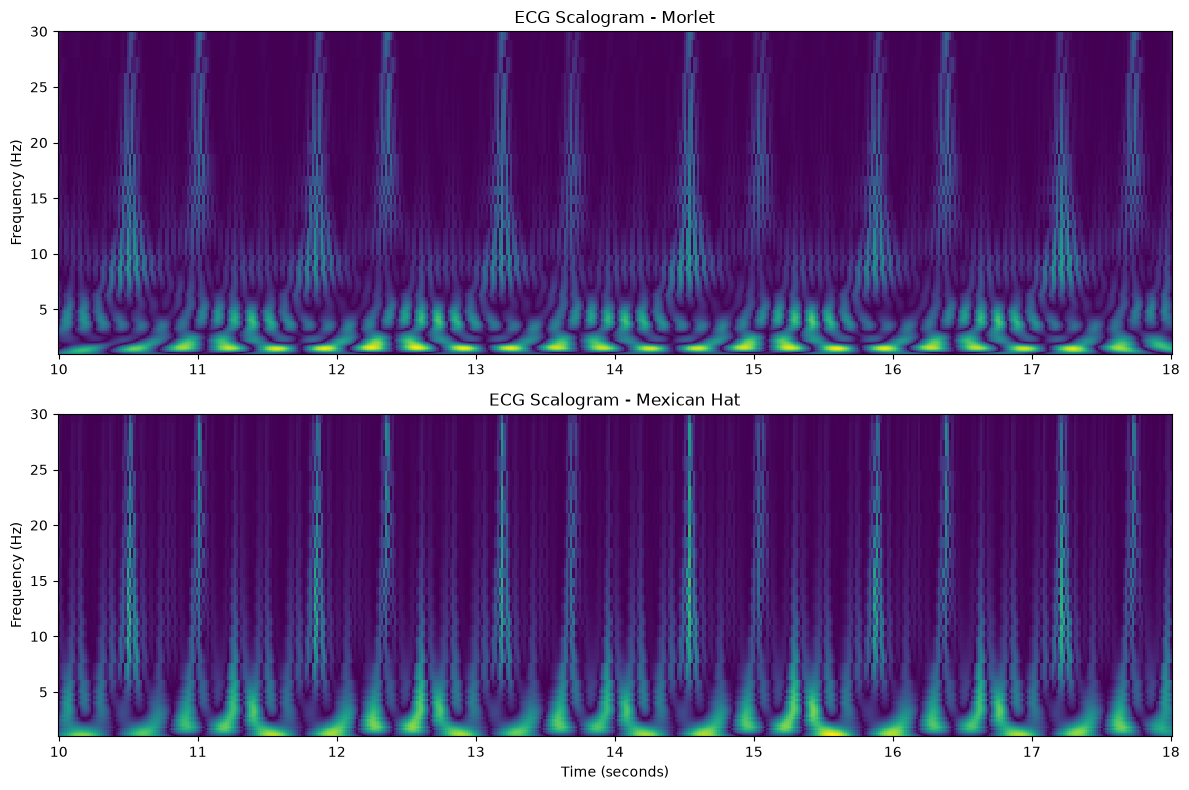

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Morlet
axes[0].pcolormesh(
    np.linspace(10, 18, len(ecg)),
    freq_morl,
    np.abs(cwt_morl),
    shading="auto"
)
axes[0].set_title("ECG Scalogram - Morlet")
axes[0].set_ylabel("Frequency (Hz)")
axes[0].set_ylim(1, 30)

# Mexican Hat
axes[1].pcolormesh(
    np.linspace(10, 18, len(ecg)),
    freq_mexh,
    np.abs(cwt_mexh),
    shading="auto"
)
axes[1].set_title("ECG Scalogram - Mexican Hat")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_ylim(1, 30)

plt.tight_layout()
plt.show()

### CWT Wavelet Comparison

Both Morlet and Mexican Hat wavelets reveal the repeated
time-frequency structure of the ECG signal within the 1–30 Hz range.
However, their coefficient patterns differ because each mother wavelet
has a different shape and frequency response.

The choice of mother wavelet therefore affects the time-frequency
representation of ECG activity.

In [37]:
from scipy.signal import butter, filtfilt

# Butterworth bandpass filter
lowcut = 0.5
highcut = 30

b, a = butter(
    N=4,
    Wn=[lowcut, highcut],
    btype="bandpass",
    fs=fs
)

ecg_butter = filtfilt(b, a, ecg)

print("Original length:", len(ecg))
print("Filtered length:", len(ecg_butter))

Original length: 500
Filtered length: 500


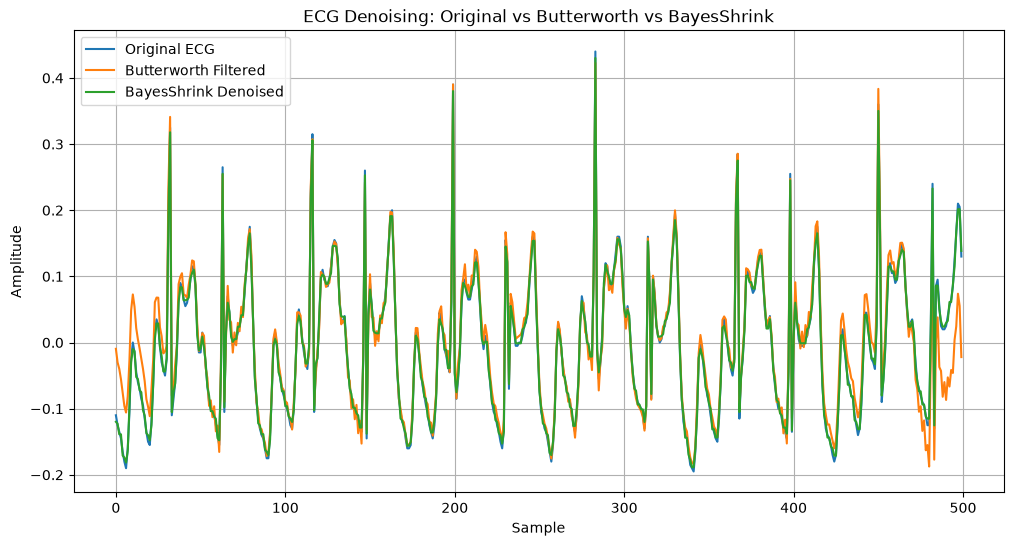

In [38]:
plt.figure(figsize=(12, 6))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_butter, label="Butterworth Filtered")
plt.plot(ecg_bayes, label="BayesShrink Denoised")

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("ECG Denoising: Original vs Butterworth vs BayesShrink")
plt.legend()
plt.grid(True)

plt.show()

In [39]:
# Butterworth metrics
rmse_butter = np.sqrt(np.mean((ecg - ecg_butter) ** 2))
mae_butter = np.mean(np.abs(ecg - ecg_butter))
corr_butter = np.corrcoef(ecg, ecg_butter)[0, 1]

# BayesShrink metrics
rmse_bayes = np.sqrt(np.mean((ecg - ecg_bayes) ** 2))
mae_bayes = np.mean(np.abs(ecg - ecg_bayes))
corr_bayes = np.corrcoef(ecg, ecg_bayes)[0, 1]

print("Butterworth:")
print(f"RMSE        : {rmse_butter:.6f}")
print(f"MAE         : {mae_butter:.6f}")
print(f"Correlation : {corr_butter:.6f}")

print("\nBayesShrink:")
print(f"RMSE        : {rmse_bayes:.6f}")
print(f"MAE         : {mae_bayes:.6f}")
print(f"Correlation : {corr_bayes:.6f}")

Butterworth:
RMSE        : 0.029046
MAE         : 0.017192
Correlation : 0.961503

BayesShrink:
RMSE        : 0.006150
MAE         : 0.005439
Correlation : 0.998444


### Wavelet Denoising vs Conventional Filtering

BayesShrink and Butterworth bandpass filtering were compared using
RMSE, MAE, and correlation with the original ECG.

For the selected segment, BayesShrink produced lower RMSE and MAE and
higher correlation than the Butterworth filter. This indicates better
preservation of the original waveform for this particular segment.

This result is specific to the selected ECG segment and does not imply
that BayesShrink is universally superior to conventional filtering.

In [40]:
from scipy.signal import find_peaks

min_distance = int(0.4 * fs)

peaks_original, _ = find_peaks(
    ecg,
    distance=min_distance,
    prominence=0.08
)

peaks_bayes, _ = find_peaks(
    ecg_bayes,
    distance=min_distance,
    prominence=0.08
)

print("Original peaks:", len(peaks_original))
print("BayesShrink peaks:", len(peaks_bayes))

Original peaks: 12
BayesShrink peaks: 12


In [41]:
print("Original peak positions:")
print(peaks_original)

print("\nBayesShrink peak positions:")
print(peaks_bayes)

print("\nPeak position differences:")
print(peaks_bayes - peaks_original)

Original peak positions:
[ 32  63 116 147 199 246 283 330 367 398 450 482]

BayesShrink peak positions:
[ 32  63 116 147 199 246 283 330 367 398 450 482]

Peak position differences:
[0 0 0 0 0 0 0 0 0 0 0 0]


### Peak Preservation

The original and BayesShrink-denoised ECG signals both contained
12 detected peaks. All peak positions were identical.

Therefore, the peak preservation rate was **100%**, indicating that
the major cardiac peaks were preserved after wavelet denoising.

In [42]:
morph_corr = np.corrcoef(ecg, ecg_bayes)[0, 1]

print(f"Morphological correlation: {morph_corr:.6f}")

Morphological correlation: 0.998444


### Morphology Preservation

The BayesShrink-denoised ECG preserved all 12 detected peaks, giving a
peak preservation rate of 100%. The peak positions showed zero-sample
difference compared with the original ECG.

The morphological correlation was 0.998444, indicating very high
similarity between the original and denoised ECG morphology.

Therefore, the major ECG features were well preserved after
BayesShrink denoising for the selected segment.

In [43]:
# Add controlled Gaussian noise at 10 dB SNR

np.random.seed(42)

target_snr_db = 10

signal_power = np.mean(ecg ** 2)
noise_power = signal_power / (10 ** (target_snr_db / 10))

noise = np.random.normal(
    0,
    np.sqrt(noise_power),
    len(ecg)
)

ecg_noisy = ecg + noise

print("Signal power:", signal_power)
print("Noise power:", noise_power)
print("Noisy ECG length:", len(ecg_noisy))

Signal power: 0.0108442
Noise power: 0.00108442
Noisy ECG length: 500


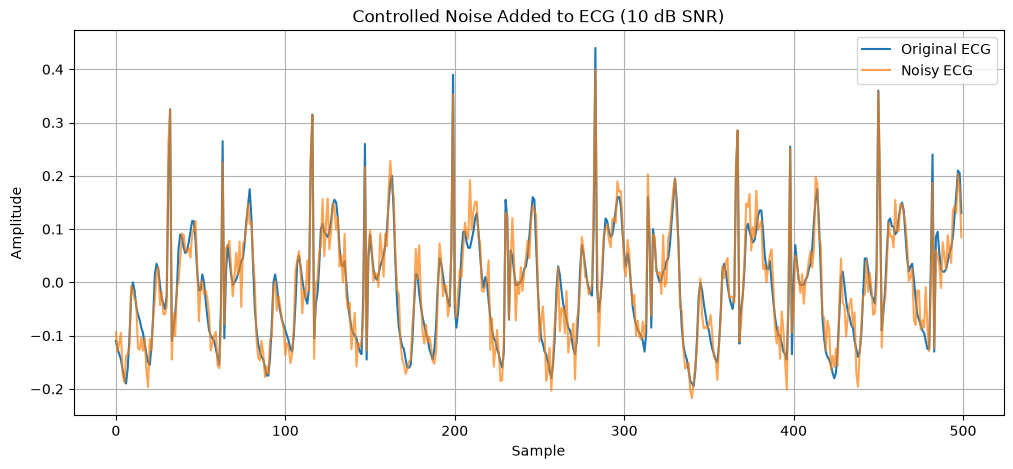

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_noisy, label="Noisy ECG", alpha=0.7)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Controlled Noise Added to ECG (10 dB SNR)")
plt.legend()
plt.grid(True)

plt.show()

In [45]:
# Calculate SNR before denoising

noise_actual = ecg_noisy - ecg

snr_before = 10 * np.log10(
    np.sum(ecg ** 2) / np.sum(noise_actual ** 2)
)

print(f"Target SNR : {target_snr_db:.2f} dB")
print(f"Actual SNR : {snr_before:.2f} dB")

Target SNR : 10.00 dB
Actual SNR : 10.17 dB


In [46]:
# DWT of noisy ECG
coeffs_noisy = pywt.wavedec(ecg_noisy, "haar", level=3)

# Estimate noise from finest detail coefficients
sigma_noisy = np.median(
    np.abs(coeffs_noisy[-1])
) / 0.6745

noise_var_noisy = sigma_noisy ** 2

print("Estimated noise sigma:", sigma_noisy)

# BayesShrink thresholds
bayes_thresholds_noisy = []

for detail in coeffs_noisy[1:]:
    signal_var = max(np.var(detail) - noise_var_noisy, 0)

    if signal_var == 0:
        threshold_bayes = np.max(np.abs(detail))
    else:
        threshold_bayes = noise_var_noisy / np.sqrt(signal_var)

    bayes_thresholds_noisy.append(threshold_bayes)

print("BayesShrink thresholds:")

for i, value in enumerate(bayes_thresholds_noisy, start=1):
    print(f"D{i}: {value:.6f}")

Estimated noise sigma: 0.039764166773503105
BayesShrink thresholds:
D1: 0.014946
D2: 0.019659
D3: 0.031484


In [47]:
# Apply BayesShrink to noisy ECG

coeffs_bayes_noisy = [coeffs_noisy[0]]

for detail, threshold_bayes in zip(
    coeffs_noisy[1:],
    bayes_thresholds_noisy
):
    coeffs_bayes_noisy.append(
        pywt.threshold(
            detail,
            threshold_bayes,
            mode="soft"
        )
    )

ecg_denoised = pywt.waverec(
    coeffs_bayes_noisy,
    "haar"
)

print("Noisy ECG length:", len(ecg_noisy))
print("Denoised ECG length:", len(ecg_denoised))

Noisy ECG length: 500
Denoised ECG length: 500


In [48]:
# Compare noisy and denoised ECG with original reference

def calculate_metrics(reference, signal):
    error = reference - signal

    rmse = np.sqrt(np.mean(error ** 2))
    mae = np.mean(np.abs(error))
    nrmse = rmse / (np.max(reference) - np.min(reference))
    prd = 100 * np.sqrt(np.sum(error ** 2) / np.sum(reference ** 2))
    correlation = np.corrcoef(reference, signal)[0, 1]

    return rmse, mae, nrmse, prd, correlation


# SNR after denoising
noise_after = ecg_denoised - ecg

snr_after = 10 * np.log10(
    np.sum(ecg ** 2) / np.sum(noise_after ** 2)
)

snr_improvement = snr_after - snr_before

# Error metrics
rmse_noisy, mae_noisy, nrmse_noisy, prd_noisy, corr_noisy = \
    calculate_metrics(ecg, ecg_noisy)

rmse_denoised, mae_denoised, nrmse_denoised, prd_denoised, corr_denoised = \
    calculate_metrics(ecg, ecg_denoised)


print(f"SNR before denoising : {snr_before:.2f} dB")
print(f"SNR after denoising  : {snr_after:.2f} dB")
print(f"SNR improvement      : {snr_improvement:.2f} dB")

print("\nNoisy ECG:")
print(f"RMSE        : {rmse_noisy:.6f}")
print(f"MAE         : {mae_noisy:.6f}")
print(f"NRMSE       : {nrmse_noisy:.6f}")
print(f"PRD         : {prd_noisy:.2f}%")
print(f"Correlation : {corr_noisy:.6f}")

print("\nDenoised ECG:")
print(f"RMSE        : {rmse_denoised:.6f}")
print(f"MAE         : {mae_denoised:.6f}")
print(f"NRMSE       : {nrmse_denoised:.6f}")
print(f"PRD         : {prd_denoised:.2f}%")
print(f"Correlation : {corr_denoised:.6f}")

SNR before denoising : 10.17 dB
SNR after denoising  : 11.24 dB
SNR improvement      : 1.07 dB

Noisy ECG:
RMSE        : 0.032282
MAE         : 0.025661
NRMSE       : 0.050837
PRD         : 31.00%
Correlation : 0.953191

Denoised ECG:
RMSE        : 0.028538
MAE         : 0.022803
NRMSE       : 0.044942
PRD         : 27.40%
Correlation : 0.961897


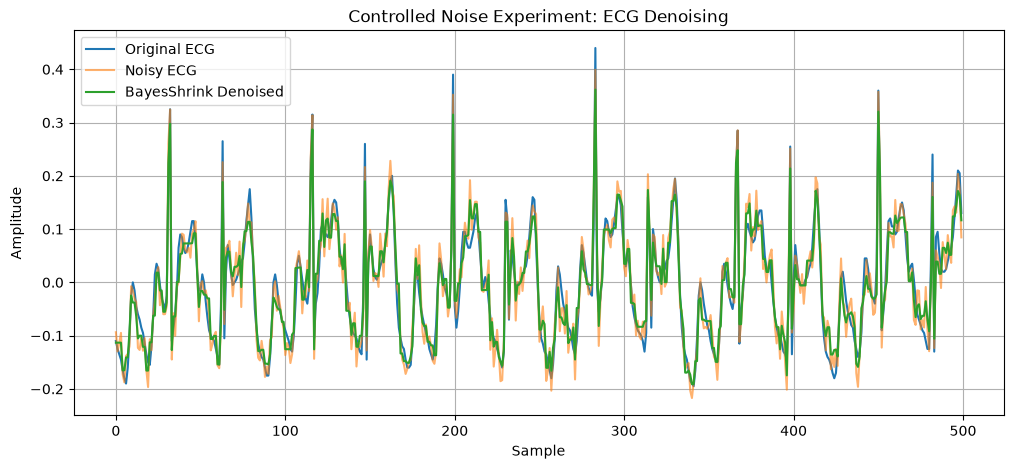

In [49]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_noisy, label="Noisy ECG", alpha=0.6)
plt.plot(ecg_denoised, label="BayesShrink Denoised")

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Controlled Noise Experiment: ECG Denoising")
plt.legend()
plt.grid(True)
plt.show()


### Observation

The controlled noise introduced visible fluctuations in the ECG signal.
After BayesShrink denoising, part of the noise was reduced while the
main ECG waveform and major peaks were preserved.

The SNR improved from 10.17 dB to 11.24 dB, giving an SNR improvement
of 1.07 dB. This indicates that BayesShrink provided moderate noise
reduction while preserving the ECG morphology.

In [50]:
# Compare wavelet detail energy

coeffs_original = pywt.wavedec(ecg, "haar", level=3)
coeffs_noisy = pywt.wavedec(ecg_noisy, "haar", level=3)
coeffs_denoised = pywt.wavedec(ecg_denoised, "haar", level=3)

for i, level in enumerate(["D3", "D2", "D1"], start=1):
    original_energy = np.sum(coeffs_original[i] ** 2)
    noisy_energy = np.sum(coeffs_noisy[i] ** 2)
    denoised_energy = np.sum(coeffs_denoised[i] ** 2)

    print(f"{level}:")
    print(f"  Original : {original_energy:.4f}")
    print(f"  Noisy    : {noisy_energy:.4f}")
    print(f"  Denoised : {denoised_energy:.4f}")

D3:
  Original : 0.8822
  Noisy    : 0.8063
  Denoised : 0.6454
D2:
  Original : 1.0093
  Noisy    : 1.0509
  Denoised : 0.7728
D1:
  Original : 0.7983
  Noisy    : 1.0264
  Denoised : 0.5635


### Effect of Controlled Noise on Wavelet Coefficients

The addition of controlled Gaussian noise increased the detail-coefficient
energy, particularly at the finest scale D1. The D1 energy increased
from 0.7983 in the original ECG to 1.0264 in the noisy ECG.

After BayesShrink denoising, the D1 energy decreased to 0.5635,
indicating suppression of high-frequency noise components.

The reduction in detail energy across the decomposition levels,
together with the improvement in SNR from 10.17 dB to 11.24 dB,
shows that wavelet denoising reduced the effect of the added noise
while retaining the main ECG waveform.

In [51]:
from scipy.stats import entropy

# Histogram-based probability distribution
hist, _ = np.histogram(ecg, bins=50, density=True)

# Normalize to probabilities
probabilities = hist / np.sum(hist)

# Remove zero probabilities
probabilities = probabilities[probabilities > 0]

shannon_entropy = entropy(probabilities, base=2)

print(f"Shannon Entropy: {shannon_entropy:.4f} bits")

Shannon Entropy: 4.8748 bits


### Shannon Entropy

The Shannon entropy of the selected ECG segment was **4.8748 bits**.
It represents the uncertainty/distribution of the signal amplitude
values across the selected segment.

In [52]:
from scipy.signal import welch

# Estimate power spectral density
frequencies, psd = welch(
    ecg,
    fs=fs,
    nperseg=256
)

# Convert PSD into probability distribution
psd_probability = psd / np.sum(psd)

# Remove zero values
psd_probability = psd_probability[psd_probability > 0]

# Spectral entropy
spectral_entropy = entropy(
    psd_probability,
    base=2
)

print(f"Spectral Entropy: {spectral_entropy:.4f} bits")

Spectral Entropy: 5.3005 bits


### Spectral Entropy

The spectral entropy of the selected ECG segment was **5.3005 bits**.
It describes how the signal power is distributed across its frequency
components.

In [53]:
import time

# BayesShrink timing
start = time.perf_counter()

for _ in range(100):
    coeffs = pywt.wavedec(ecg_noisy, "haar", level=3)

    coeffs_denoised = [coeffs[0]]

    for detail, threshold_bayes in zip(
        coeffs[1:], bayes_thresholds_noisy
    ):
        coeffs_denoised.append(
            pywt.threshold(detail, threshold_bayes, mode="soft")
        )

    pywt.waverec(coeffs_denoised, "haar")

bayes_time = (time.perf_counter() - start) / 100


# Butterworth timing
start = time.perf_counter()

for _ in range(100):
    filtfilt(b, a, ecg_noisy)

butter_time = (time.perf_counter() - start) / 100


print(f"BayesShrink time    : {bayes_time*1000:.4f} ms")
print(f"Butterworth time    : {butter_time*1000:.4f} ms")

BayesShrink time    : 0.0826 ms
Butterworth time    : 0.0924 ms


### Computational Time

The average computational time was measured over 100 repetitions for
the same 500-sample ECG segment.

- BayesShrink: **0.0826 ms**
- Butterworth filtering: **0.0924 ms**

For this experiment, both methods required very little computation,
with BayesShrink showing slightly lower execution time.

In [54]:
# PPG: 3-level DWT

ppg_coeffs = pywt.wavedec(ppg, "haar", level=3)

cA3_ppg, cD3_ppg, cD2_ppg, cD1_ppg = ppg_coeffs

print("Original samples:", len(ppg))
print("A3:", len(cA3_ppg))
print("D3:", len(cD3_ppg))
print("D2:", len(cD2_ppg))
print("D1:", len(cD1_ppg))


Original samples: 500
A3: 63
D3: 63
D2: 125
D1: 250


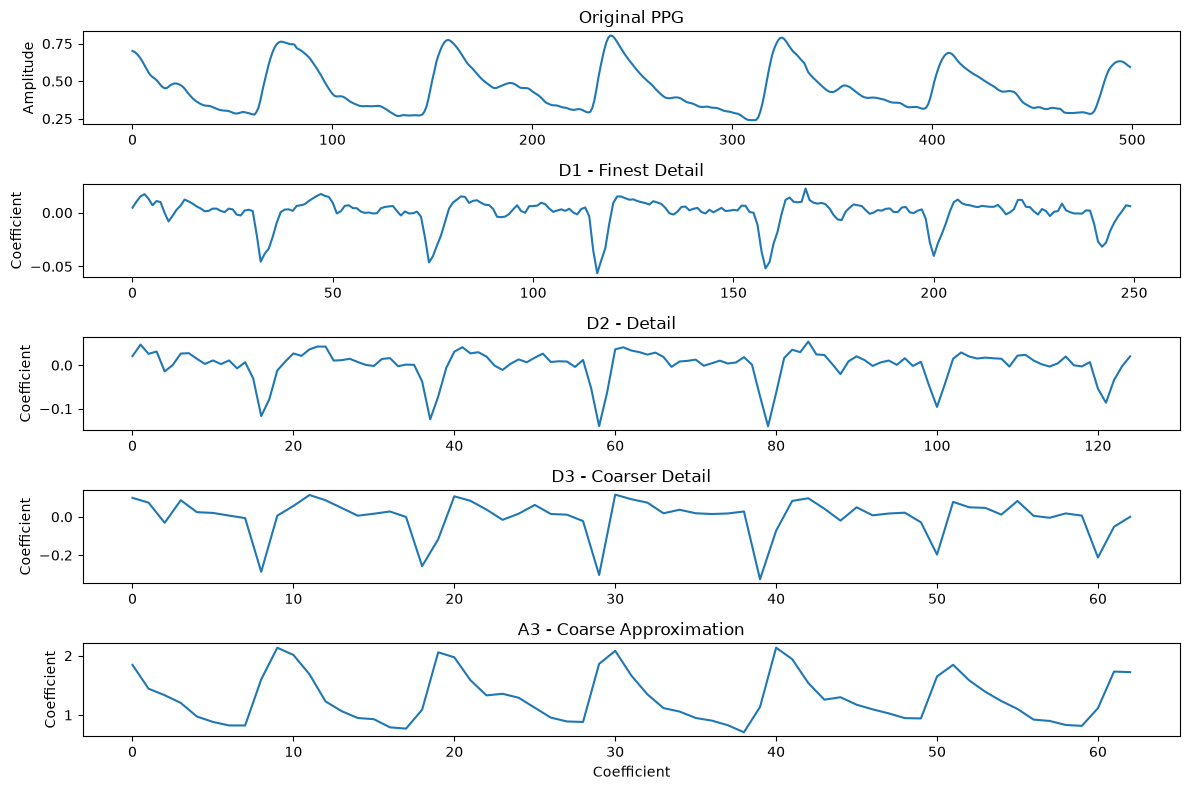

In [55]:
plt.figure(figsize=(12, 8))

plt.subplot(5, 1, 1)
plt.plot(ppg)
plt.title("Original PPG")
plt.ylabel("Amplitude")

plt.subplot(5, 1, 2)
plt.plot(cD1_ppg)
plt.title("D1 - Finest Detail")
plt.ylabel("Coefficient")

plt.subplot(5, 1, 3)
plt.plot(cD2_ppg)
plt.title("D2 - Detail")
plt.ylabel("Coefficient")

plt.subplot(5, 1, 4)
plt.plot(cD3_ppg)
plt.title("D3 - Coarser Detail")
plt.ylabel("Coefficient")

plt.subplot(5, 1, 5)
plt.plot(cA3_ppg)
plt.title("A3 - Coarse Approximation")
plt.xlabel("Coefficient")
plt.ylabel("Coefficient")

plt.tight_layout()
plt.show()

In [56]:
# PPG wavelet energy

ppg_energies = {
    "D1": np.sum(cD1_ppg ** 2),
    "D2": np.sum(cD2_ppg ** 2),
    "D3": np.sum(cD3_ppg ** 2),
    "A3": np.sum(cA3_ppg ** 2)
}

for name, value in ppg_energies.items():
    print(f"{name}: {value:.4f}")

D1: 0.0434
D2: 0.1631
D3: 0.6002
A3: 114.1582


### PPG Wavelet Energy

The PPG wavelet decomposition shows that most of the signal energy is
concentrated in the approximation component A3, with comparatively lower
energy in the detail components.

This indicates that the selected PPG segment is dominated by slower,
large-scale waveform variations, while the detail coefficients represent
finer changes in the pulse morphology.

In [57]:
# PPG wavelet entropy

ppg_entropies = {
    "D1": wavelet_entropy(cD1_ppg),
    "D2": wavelet_entropy(cD2_ppg),
    "D3": wavelet_entropy(cD3_ppg),
    "A3": wavelet_entropy(cA3_ppg)
}

for name, value in ppg_entropies.items():
    print(f"{name}: {value:.4f}")

D1: 5.8785
D2: 4.9667
D3: 3.9886
A3: 5.7110


### PPG Wavelet Entropy

The wavelet entropy varies across the PPG decomposition levels.
The highest entropy among the detail components occurs at D1 (5.8785),
while D3 has the lowest entropy (3.9886).

This indicates that the distribution of coefficient energy changes
with scale. Combined with the energy analysis, the results show that
the PPG signal is dominated by coarse-scale energy while its finer
components exhibit different levels of energy distribution.

In [58]:
# Relative wavelet energy: ECG vs PPG

ecg_total = sum(energies.values())
ppg_total = sum(ppg_energies.values())

print("ECG relative energy:")
for name, value in energies.items():
    print(f"{name}: {100 * value / ecg_total:.2f}%")

print("\nPPG relative energy:")
for name, value in ppg_energies.items():
    print(f"{name}: {100 * value / ppg_total:.2f}%")

ECG relative energy:
D1: 14.39%
D2: 18.19%
D3: 15.90%
A3: 51.52%

PPG relative energy:
D1: 0.04%
D2: 0.14%
D3: 0.52%
A3: 99.30%


### ECG vs PPG Relative Energy

The ECG energy is distributed across multiple wavelet scales, with
51.52% of the energy in the approximation component A3 and the remaining
energy distributed across D1, D2 and D3.

In contrast, the PPG signal shows a strong concentration of energy in
A3 (99.30%), with only a small fraction present in the detail
components.

This indicates that the selected PPG segment is dominated by
coarse-scale variations, whereas the ECG contains relatively more
fine-scale information.

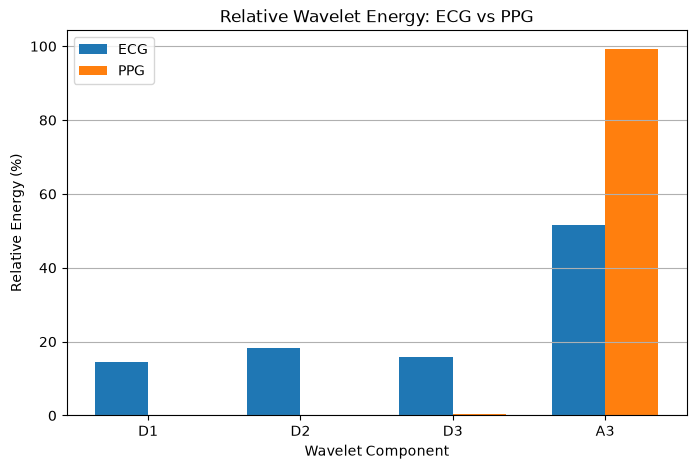

In [59]:
components = ["D1", "D2", "D3", "A3"]

ecg_relative = [14.39, 18.19, 15.90, 51.52]
ppg_relative = [0.04, 0.14, 0.52, 99.30]

x = np.arange(len(components))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, ecg_relative, width, label="ECG")
plt.bar(x + width/2, ppg_relative, width, label="PPG")

plt.xticks(x, components)
plt.xlabel("Wavelet Component")
plt.ylabel("Relative Energy (%)")
plt.title("Relative Wavelet Energy: ECG vs PPG")
plt.legend()
plt.grid(axis="y")

plt.show()

### Observation

The relative wavelet energy shows a clear difference between ECG and PPG.

For ECG, the energy is distributed across both approximation and detail
components, with 51.52% in A3 and 48.48% across D1, D2 and D3.

For PPG, 99.30% of the energy is concentrated in A3, while only 0.70%
is distributed across the detail components.

This indicates that the selected PPG segment is strongly dominated by
coarse-scale variations, whereas the ECG contains substantially more
fine-scale information.

In [60]:
# PPG CWT using Morlet wavelet

target_freqs = np.geomspace(1, 30, 64)

scales_ppg = pywt.frequency2scale(
    "morl",
    target_freqs / fs
)

cwt_ppg, freq_ppg = pywt.cwt(
    ppg,
    scales_ppg,
    "morl",
    sampling_period=1/fs
)

print("CWT shape:", cwt_ppg.shape)
print("Frequency range:", freq_ppg.min(), "to", freq_ppg.max(), "Hz")

CWT shape: (64, 500)
Frequency range: 1.0 to 30.0 Hz


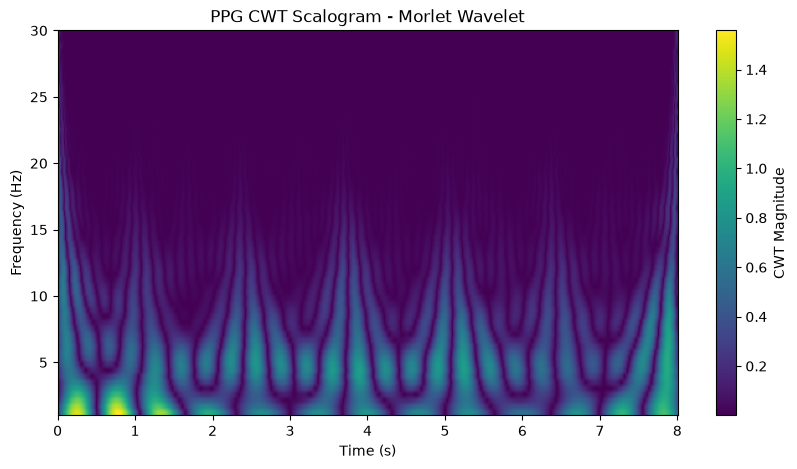

In [61]:
plt.figure(figsize=(10, 5))

plt.imshow(
    np.abs(cwt_ppg),
    extent=[0, len(ppg) / fs, freq_ppg.min(), freq_ppg.max()],
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="CWT Magnitude")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("PPG CWT Scalogram - Morlet Wavelet")

plt.show()


### Observation

The Morlet CWT scalogram shows repeated time-frequency patterns
throughout the PPG segment. The strongest CWT activity is concentrated
mainly in the lower-frequency region and repeats with the periodic
pulse waveform.

This demonstrates that CWT can represent the time-varying frequency
content of the PPG signal at different scales.

In [62]:
# PPG CWT: Morlet vs Mexican Hat

scales_morl_ppg = pywt.frequency2scale(
    "morl",
    target_freqs / fs
)

scales_mexh_ppg = pywt.frequency2scale(
    "mexh",
    target_freqs / fs
)

cwt_morl_ppg, freq_morl_ppg = pywt.cwt(
    ppg,
    scales_morl_ppg,
    "morl",
    sampling_period=1/fs
)

cwt_mexh_ppg, freq_mexh_ppg = pywt.cwt(
    ppg,
    scales_mexh_ppg,
    "mexh",
    sampling_period=1/fs
)

print("Morlet:", freq_morl_ppg.min(), "to", freq_morl_ppg.max(), "Hz")
print("Mexican Hat:", freq_mexh_ppg.min(), "to", freq_mexh_ppg.max(), "Hz")

Morlet: 1.0 to 30.0 Hz
Mexican Hat: 1.0 to 30.0 Hz


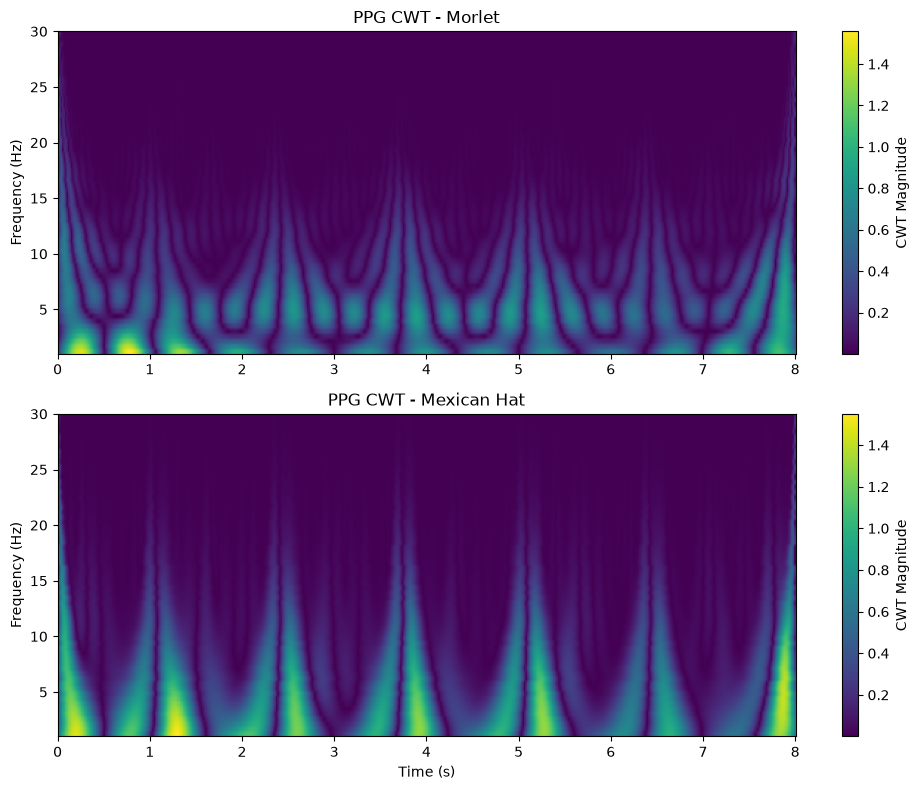

In [63]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Morlet
im1 = axes[0].imshow(
    np.abs(cwt_morl_ppg),
    extent=[0, len(ppg) / fs, 1, 30],
    aspect="auto",
    origin="lower"
)
axes[0].set_title("PPG CWT - Morlet")
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im1, ax=axes[0], label="CWT Magnitude")

# Mexican Hat
im2 = axes[1].imshow(
    np.abs(cwt_mexh_ppg),
    extent=[0, len(ppg) / fs, 1, 30],
    aspect="auto",
    origin="lower"
)
axes[1].set_title("PPG CWT - Mexican Hat")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(im2, ax=axes[1], label="CWT Magnitude")

plt.tight_layout()
plt.show()

### CWT Wavelet Comparison

Both Morlet and Mexican Hat wavelets reveal the repeated time-frequency
structure of the PPG signal within the 1–30 Hz range.

The Morlet wavelet produces a broader and more detailed time-frequency
representation, while the Mexican Hat wavelet produces more concentrated
responses around the pulse-related components.

Thus, the choice of mother wavelet affects the time-frequency
representation of PPG activity.

## 10. Final Consolidated ECG Results

The following table summarizes the main results obtained from ECG
reconstruction, wavelet denoising, threshold selection, and conventional
filtering.

| Analysis | Method | RMSE | MAE | NRMSE | PRD (%) | Correlation |
|---|---|---:|---:|---:|---:|---:|
| Reconstruction | Haar | 0.000000 | — | — | — | 1.000000 |
| Reconstruction | Daubechies (db4) | 0.000000 | — | — | — | 1.000000 |
| Reconstruction | Symlet (sym4) | 0.000000 | — | — | — | 1.000000 |
| Reconstruction | Coiflet (coif1) | 0.000000 | — | — | — | 1.000000 |
| Denoising | Fixed Hard Threshold | 0.027776 | 0.021805 | — | — | 0.963670 |
| Denoising | Fixed Soft Threshold | 0.046168 | 0.036208 | — | — | 0.903918 |
| Thresholding | Universal Threshold | 0.023836 | 0.018818 | — | — | 0.973376 |
| Thresholding | BayesShrink | **0.006150** | **0.005439** | **0.009684** | **5.9053** | **0.998444** |
| Conventional Filtering | Butterworth | 0.029046 | 0.017192 | — | — | 0.961503 |

## Controlled Noise Experiment

A controlled Gaussian noise experiment was performed at a target SNR of
10 dB. The original ECG was used as the known reference.

| Condition | RMSE | MAE | NRMSE | PRD (%) | Correlation | SNR (dB) |
|---|---:|---:|---:|---:|---:|---:|
| Noisy ECG | 0.032282 | 0.025661 | 0.050837 | 31.00 | 0.953191 | 10.17 |
| BayesShrink Denoised | 0.028538 | 0.022803 | 0.044942 | 27.40 | 0.961897 | **11.24** |
| Improvement | ↓ 0.003744 | ↓ 0.002858 | ↓ 0.005895 | ↓ 3.60 | ↑ 0.008706 | **+1.07** |

## Other Important ECG Results

| Metric | Result |
|---|---:|
| Sampling Frequency | 62.4725 Hz |
| Analysis Window | 10–18 s |
| Number of Samples | 500 |
| Decomposition | Haar, Level 3 |
| D1 Relative Energy | 14.39% |
| D2 Relative Energy | 18.19% |
| D3 Relative Energy | 15.90% |
| A3 Relative Energy | 51.52% |
| Shannon Entropy | 4.8748 bits |
| Spectral Entropy | 5.3005 bits |
| Original Detected Peaks | 12 |
| BayesShrink Detected Peaks | 12 |
| Peak Preservation | 100% |
| Morphological Correlation | 0.998444 |
| BayesShrink Time | 0.0826 ms |
| Butterworth Time | 0.0924 ms |

### ECG Results Summary

BayesShrink provided the best waveform preservation among the tested
denoising approaches for the selected ECG segment. It achieved an RMSE
of 0.006150 and correlation of 0.998444 with the recorded ECG.

In the controlled-noise experiment, BayesShrink improved the SNR from
10.17 dB to 11.24 dB, corresponding to an improvement of 1.07 dB.
All 12 detected ECG peaks were preserved, indicating good morphology
preservation for the selected segment.


## Final Consolidated PPG Results

The following table summarizes the main results obtained from the
multiscale wavelet analysis and CWT of the selected PPG segment.

| Analysis | Result |
|---|---:|
| Sampling Frequency | 62.4725 Hz |
| Analysis Window | 10–18 s |
| Number of Samples | 500 |
| Decomposition | Haar, Level 3 |
| D1 Relative Energy | 0.04% |
| D2 Relative Energy | 0.14% |
| D3 Relative Energy | 0.52% |
| A3 Relative Energy | 99.30% |
| D1 Wavelet Entropy | 5.8785 |
| D2 Wavelet Entropy | 4.9667 |
| D3 Wavelet Entropy | 3.9886 |
| A3 Wavelet Entropy | 5.7110 |
| CWT Frequency Range | 1–30 Hz |
| CWT Wavelets | Morlet, Mexican Hat |

### PPG Results Summary

The PPG signal showed a strong concentration of wavelet energy in the
coarse approximation component A3 (99.30%), while the detail components
contained only a small fraction of the total energy.

The CWT analysis using Morlet and Mexican Hat wavelets revealed the
repeated time-frequency structure of the PPG pulse waveform. The results
demonstrate that the selected PPG signal is dominated by coarse-scale
variations while still exhibiting meaningful multiscale structure.


# 11. Overall Results and Discussion

The wavelet analysis showed clear differences between the multiscale
characteristics of ECG and PPG signals.

### ECG

The ECG signal showed energy distributed across multiple wavelet scales.
The approximation component A3 contained 51.52% of the total energy,
while D1, D2 and D3 contained 14.39%, 18.19% and 15.90%, respectively.

Among the tested denoising methods, BayesShrink provided the best
preservation of the recorded ECG waveform, with RMSE = 0.006150 and
correlation = 0.998444.

In the controlled-noise experiment, BayesShrink improved the SNR from
10.17 dB to 11.24 dB, giving an improvement of 1.07 dB. All 12 detected
ECG peaks were preserved.

### PPG

The PPG signal showed a much stronger concentration of energy at the
coarse scale. The A3 component contained 99.30% of the total wavelet
energy, while D1, D2 and D3 together contained only 0.70%.

The CWT analysis using Morlet and Mexican Hat wavelets revealed the
repeated time-frequency structure of the PPG pulse waveform.

### ECG vs PPG

The results indicate that ECG contains substantially more fine-scale
information than the selected PPG segment. In contrast, PPG is strongly
dominated by slower, coarse-scale variations.

Overall, DWT was useful for multiscale decomposition and energy analysis,
while CWT provided a time-frequency representation of the physiological
signals. Wavelet denoising also demonstrated the ability to reduce
noise while preserving important ECG morphology.

## 12. Limitations

- The analysis was performed on a relatively short 8-second ECG/PPG
  segment.
- The recorded ECG was not a known noise-free ground truth; therefore,
  denoising metrics against the recorded signal primarily measure signal
  preservation.
- The controlled-noise experiment used synthetic Gaussian noise and
  therefore does not represent every type of real physiological noise.
- Results may vary for different patients, signal segments, noise levels,
  wavelets and threshold parameters.